In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [2]:
!pip install catboost
!pip install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 98.9 MB/s  0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [optuna]


In [3]:
from catboost import CatBoostClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
import optuna

In [4]:
train = pd.read_csv('train_fe.csv')
test = pd.read_csv('test_fe.csv')

In [5]:
X = train.drop(columns=['id', 'PitNextLap'])
y = train['PitNextLap']
X_test = test.drop(columns=['id'])

cat_cols = ['Driver', 'Compound', 'Race']

for col in cat_cols:
    X[col] = X[col].astype(str)
    X_test[col] = X_test[col].astype(str)

oof_preds_cb = np.zeros(len(X))
test_preds_cb = np.zeros(len(X_test))

In [6]:
def objective(trial):
    param = {
        'iterations': 1000,
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
        'depth': trial.suggest_int('depth', 4, 8),
        'l2_leaf_reg': trial.suggest_float('l2_leaf_reg', 1e-3, 10.0, log=True),
        'bagging_temperature': trial.suggest_float('bagging_temperature', 0.0, 1.0),
        'auto_class_weights': 'Balanced',
        'random_seed': 42,
        'task_type': 'GPU',
        'verbose': 0
    }

    skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
    cv_scores = []

    for train_idx, val_idx in skf.split(X, y):
        X_tr, y_tr = X.iloc[train_idx], y.iloc[train_idx]
        X_va, y_va = X.iloc[val_idx], y.iloc[val_idx]

        model = CatBoostClassifier(**param)

        model.fit(
            X_tr, y_tr,
            eval_set=(X_va, y_va),
            cat_features=cat_cols,
            early_stopping_rounds=50,
            use_best_model=True
        )

        preds = model.predict_proba(X_va)[:, 1]
        cv_scores.append(roc_auc_score(y_va, preds))

    return np.mean(cv_scores)

study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=20)

print("\nBest found hyperparameters:")
best_params = study.best_params
for key, value in best_params.items():
    print(f"'{key}': {value},")
print(f"\n Best average ROC AUC (3-fold): {study.best_value:.5f}")



[I 2026-11-05 09:26:53,921] A new study created in memory with name: no-name-90845c29-6ff4-430a-829b-cbe4c6e1afae
[I 2026-11-05 09:27:30,194] Trial 0 finished with value: 0.9308341215854589 and parameters: {'learning_rate': 0.011298328780649219, 'depth': 4, 'l2_leaf_reg': 0.0060857514106968736, 'bagging_temperature': 0.46322240770606316}. Best is trial 0 with value: 0.9308341215854589.
[I 2026-11-05 09:28:50,357] Trial 1 finished with value: 0.9471846853520388 and parameters: {'learning_rate': 0.07918758792058346, 'depth': 8, 'l2_leaf_reg': 6.957842039818976, 'bagging_temperature': 0.1554608212008196}. Best is trial 1 with value: 0.9471846853520388.
[I 2026-11-05 09:29:45,142] Trial 2 finished with value: 0.9411913586356749 and parameters: {'learning_rate': 0.023971496732194526, 'depth': 6, 'l2_leaf_reg': 0.07359509687941762, 'bagging_temperature': 0.9597329633389622}. Best is trial 1 with value: 0.9471846853520388.
[I 2026-11-05 09:30:21,289] Trial 3 finished with value: 0.93150842168


Best found hyperparameters:
'learning_rate': 0.0863916625658299,
'depth': 8,
'l2_leaf_reg': 5.75420144926539,
'bagging_temperature': 0.10402866707646777,

 Best average ROC AUC (3-fold): 0.94720


In [7]:

final_params = {
    'iterations': 1000,
    'learning_rate': best_params['learning_rate'],
    'depth': best_params['depth'],
    'l2_leaf_reg': best_params['l2_leaf_reg'],
    'bagging_temperature': best_params['bagging_temperature'],
    'auto_class_weights': 'Balanced',
    'random_seed': 42,
    'task_type': 'GPU',
    'verbose': 200
}

oof_preds_cb = np.zeros(len(X))
test_preds_cb = np.zeros(len(X_test))

skf_final = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for fold, (train_idx, val_idx) in enumerate(skf_final.split(X, y)):
    X_tr, y_tr = X.iloc[train_idx], y.iloc[train_idx]
    X_va, y_va = X.iloc[val_idx], y.iloc[val_idx]

    model_cb = CatBoostClassifier(**final_params)

    model_cb.fit(
        X_tr, y_tr,
        eval_set=(X_va, y_va),
        cat_features=cat_cols,
        early_stopping_rounds=100,
        use_best_model=True
    )

    val_probs = model_cb.predict_proba(X_va)[:, 1]
    oof_preds_cb[val_idx] = val_probs
    test_preds_cb += model_cb.predict_proba(X_test)[:, 1] / skf_final.n_splits

    print(f"Fold {fold+1} CatBoost ROC AUC: {roc_auc_score(y_va, val_probs):.5f}")

total_auc_cb = roc_auc_score(y, oof_preds_cb)
print(f"\n OOF ROC AUC (CatBoost Optuna): {total_auc_cb:.5f}")



0:	learn: 0.6242019	test: 0.6241648	best: 0.6241648 (0)	total: 29.8ms	remaining: 29.7s
200:	learn: 0.2892830	test: 0.2941031	best: 0.2941031 (200)	total: 5.76s	remaining: 22.9s
400:	learn: 0.2697983	test: 0.2852095	best: 0.2852095 (400)	total: 11.7s	remaining: 17.4s
600:	learn: 0.2565015	test: 0.2828160	best: 0.2828160 (600)	total: 17.4s	remaining: 11.6s
800:	learn: 0.2461388	test: 0.2818694	best: 0.2818471 (793)	total: 23.4s	remaining: 5.81s
999:	learn: 0.2369754	test: 0.2817275	best: 0.2815883 (909)	total: 29.2s	remaining: 0us
bestTest = 0.2815883235
bestIteration = 909
Shrink model to first 910 iterations.
Fold 1 CatBoost ROC AUC: 0.94917
0:	learn: 0.6245962	test: 0.6250664	best: 0.6250664 (0)	total: 29.4ms	remaining: 29.4s
200:	learn: 0.2872263	test: 0.3001767	best: 0.3001767 (200)	total: 5.8s	remaining: 23s
400:	learn: 0.2687422	test: 0.2923908	best: 0.2923908 (400)	total: 11.6s	remaining: 17.4s
600:	learn: 0.2557537	test: 0.2896866	best: 0.2896866 (600)	total: 17.5s	remaining: 11

FileNotFoundError: [Errno 2] No such file or directory: 'sample_submission.csv'

In [8]:
submission_cb = pd.read_csv('sample_submission.csv')
submission_cb['PitNextLap'] = test_preds_cb
submission_cb.to_csv('catboost_optuna_submission.csv', index=False)

/tmp/ipykernel_5881/3482236254.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=fi_cb_df.head(15), x='Importance', y='Feature', palette='crest')


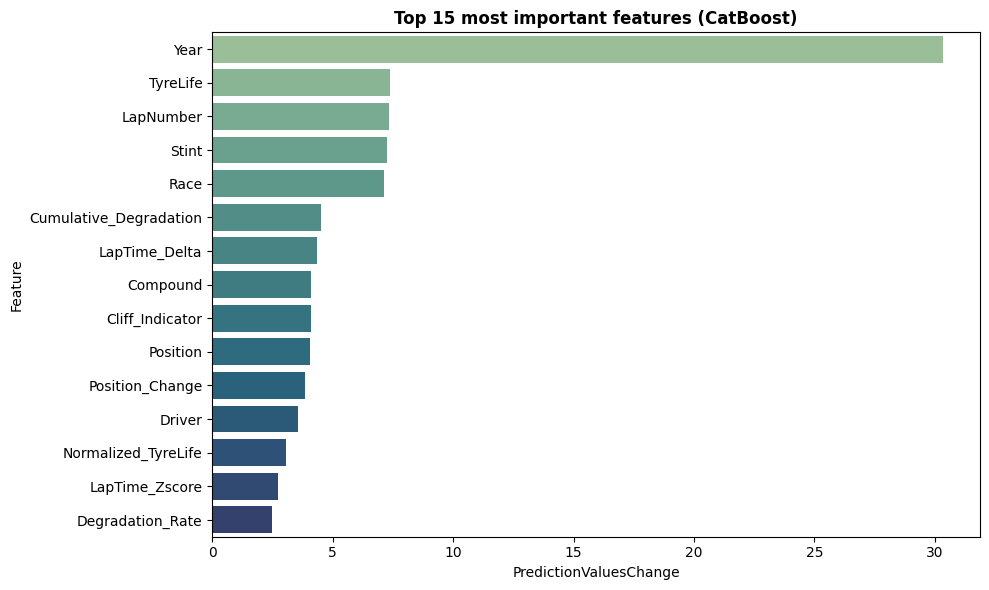

In [9]:
importances = model_cb.get_feature_importance(type='PredictionValuesChange')

fi_cb_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(data=fi_cb_df.head(15), x='Importance', y='Feature', palette='crest')
plt.title("Top 15 most important features (CatBoost)", weight='bold')
plt.xlabel("PredictionValuesChange")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()